# 1장 2강: TF-IDF와 키워드 분석 — 실습문제


## 실습 목표

- 한 문서 안의 등장 횟수인 TF와, 해당 단어가 등장한 문서 수인 DF를 구분할 수 있다.
- 교안의 기본 수식 `IDF = ln(N / DF)`, `TF-IDF = TF × IDF`를 적용할 수 있다.
- `TfidfVectorizer`로 문서별 TF-IDF 행렬을 만들고 상위 키워드 후보를 추출할 수 있다.
- 가로 막대그래프에서 단어별 가중치를 비교하고 원문·도메인 맥락을 근거로 해석할 수 있다.
- 문서 수가 적을 때의 가중치 변화와 TF-IDF의 의미 해석 한계를 설명할 수 있다.

## 실습 환경 / 데이터

- Python 3, Jupyter Notebook 또는 VS Code 노트북
- pandas, scikit-learn, matplotlib, Python 기본 모듈 math·pathlib
- `reviews.csv`, `review_labels.csv`, `aspect_labels.csv`를 노트북과 같은 폴더에 둡니다.
- 다른 위치라면 준비 코드의 `DATA_DIR`만 바꿉니다.

| 파일 | 이번 실습에서의 역할 | 주요 컬럼 |
|---|---|---|
| reviews.csv | 리뷰 하나를 문서 하나로 사용하여 TF-IDF 계산 | review_id, review_text, source, domain, category, product_name |
| review_labels.csv | 선택한 리뷰의 기존 전체 라벨을 함께 확인 | review_id, sentiment_code |
| aspect_labels.csv | 원문 해석 시 속성별 근거 표현을 함께 확인 | review_id, aspect_no, aspect, evidence_text, sentiment_code |

라벨과 속성명은 이미 제공된 정보입니다. **TF-IDF의 입력은 리뷰 본문이며 라벨·근거 문장을 본문에 붙이지 않습니다.** 기존 라벨을 이번 실습의 예측 결과로 제시하거나, TF-IDF 값과 감정 코드를 같은 값으로 해석하지 않습니다. 코드의 의미를 임의로 정하기보다 실제 근거 문장을 읽어 해석합니다.

### 교안 범위와 계산 기준

| 구분 | 계산·활용 범위 |
|---|---|
| 필수 1 | 교안에 제시된 짧은 문서로 TF·DF·기본 IDF·기본 TF-IDF 계산 |
| 필수 2 | 실제 리뷰 100개에 교안의 기본 TfidfVectorizer 사용, 상위 키워드·막대그래프·원문 해석 |
| 과제 1 | 같은 행렬의 다른 리뷰에 동일 절차 적용, 교안의 소규모 문서 예시로 IDF 변화 확인 |

기본 수식으로 직접 계산한 값과 라이브러리의 기본 설정으로 계산한 값은 다릅니다. 교안에서 설명한 **IDF 보정과 벡터 정규화의 적용 여부**만 구분하며, 그 세부 수식이나 추가 설정은 다루지 않습니다.

교안의 짧은 예시는 이미 단어로 정리된 텍스트입니다. 제공 CSV에는 원문이 있으므로 실제 데이터 실습에서는 앞뒤 공백만 정리한 본문에 교안의 기본 코드를 적용합니다. 형태소 분석기를 실행하지 않아 조사·어미가 붙은 표현이나 영문 표현도 후보가 될 수 있습니다. 이를 “명사 추출 결과”라고 부르지 않습니다. 형태소 분석기 설치, 추가 전처리 기법, 임베딩 계산, 분류 모델, LLM API는 출제하지 않습니다.


## 시작 전에 읽는 개념 정리

리뷰가 많으면 모든 글을 처음부터 읽기 전에 **어떤 표현이 각 리뷰의 특징을 보여주는지** 살펴보고 싶어집니다. TF-IDF는 한 문서에서 얼마나 반복되었는지와, 다른 문서에도 흔히 나타나는지를 함께 사용하여 표현별 가중치를 구합니다. 가중치가 높은 표현을 원문을 읽기 위한 후보로 활용합니다.

| 용어 | 쉽게 풀어쓴 뜻 | 이번 실습에서의 대상 |
|---|---|---|
| 문서 | 분석에서 하나로 다룰 글 | 실제 데이터에서는 리뷰 한 개 |
| 문서 집합 | 함께 비교하는 문서들의 묶음 | 필수 1은 예시 3개, 필수 2·과제의 실제 분석은 리뷰 100개 |
| 토큰 | 정한 기준으로 나눈 텍스트 조각 | 필수 1에서는 공백으로 나눈 배송·만족 등의 단어 |
| TF | 특정 문서 하나 안에서 해당 단어가 나온 횟수 | 같은 단어가 두 번 나오면 이번 기본 계산에서는 2 |
| DF | 그 단어가 한 번 이상 나온 문서의 수 | 한 문서에서 열 번 나와도 그 문서로 늘어나는 DF는 1 |
| N | 비교하는 전체 문서 수 | 모든 단어의 등장 횟수를 더한 수가 아님 |
| IDF | 여러 문서 중 얼마나 드문 표현인지 반영하는 값 | 같은 N에서 DF가 작을수록 기본 IDF가 커짐 |
| TF-IDF | 문서 안의 반복과 문서 집합에서의 희소성을 함께 반영한 가중치 | 이번 기본 수식에서는 TF와 IDF를 곱함 |
| 가중치 | 분석 기준에 따라 계산한 수치 | 등장 횟수·감정 확률과 구분 |
| 행렬 | 숫자를 행과 열로 배치한 구조 | 리뷰별·표현별 가중치를 정리한 표 |
| 벡터화 | 텍스트를 여러 숫자로 표현하는 과정 | 각 리뷰를 단어별 TF-IDF 값으로 표현 |
| 키워드 후보 | 원문을 이해하는 데 도움이 될지 검토할 표현 | 값이 높다는 이유만으로 최종 핵심어로 확정하지 않음 |
| 도메인 | 자료가 다루는 분야 | 이번 100개 리뷰는 패션 분야 |

### TF와 DF는 세는 대상이 다릅니다

TF를 셀 때는 **한 문서 안에서 몇 번인가**를 묻습니다. DF를 셀 때는 **전체 문서 중 몇 문서인가**를 묻습니다. 전체 등장 횟수는 모든 문서 안의 반복을 합친 값이므로 이 둘과도 구분해야 합니다.

이번 기본 수식의 TF는 단순 등장 횟수로 정의합니다. TF를 계산하는 다른 방식까지 추가로 익힐 필요는 없습니다. 수식과 코드에서 사용하는 정의를 맞추는 것이 우선입니다.

### 수식과 기호를 읽는 방법

| 표시 | 읽는 방법 | 구분할 점 |
|---|---|---|
| `t`, `d` | 특정 단어, 특정 문서 | 이 수식의 t는 시간 번호가 아님 |
| `TF(t, d)` | 문서 d에서 단어 t가 나온 횟수 | 어떤 문서의 값인지 함께 적어야 함 |
| `DF(t)` | 단어 t가 들어 있는 문서의 수 | 같은 문서 안 반복을 중복해서 세지 않음 |
| `N / DF(t)` | 전체 문서 수를 등장 문서 수로 나눈 비율 | 단어가 드물수록 이 비율이 커짐 |
| `ln(...)` | 자연로그 함수에 괄호 안 값을 넣음 | Python의 `math.log()`로 계산 |
| `TF × IDF` | 두 값을 곱함 | 더하거나 평균 내는 식이 아님 |

자연로그는 양수 값을 다른 크기의 수로 바꾸는 함수입니다. 여기서는 **입력이 커질수록 결과도 커지고, ln(1)=0**이라는 성질을 알면 계산 흐름을 읽을 수 있습니다. 자연로그 값을 손으로 근사하거나 미분하는 문제는 없습니다. 예를 들어 전체 10개 중 2개에 나온 단어라면 `10/2=5`를 먼저 계산한 뒤 `log(5)`를 구합니다. 5 자체가 최종 IDF는 아닙니다.

### 이번 실습의 두 계산을 구분하세요

| 구분 | 기본 수식 연습 | 실제 리뷰 분석 |
|---|---|---|
| 대상 | 교안의 짧은 예시 문서 | 제공 CSV의 앞 100개 리뷰 |
| 방법 | TF × ln(N/DF)를 직접 계산 | TfidfVectorizer 기본 설정 |
| 목적 | 횟수·문서 수·희소성의 관계 이해 | 문서별 키워드 후보 추출과 원문 해석 |
| 숫자를 읽을 때 | 보정·정규화 없는 기본 계산값 | IDF 보정과 벡터 정규화가 적용된 가중치 |

라이브러리 기본값에는 계산을 보정하는 과정과, 문서 벡터의 크기를 일정한 기준으로 맞추는 과정이 들어갑니다. 이를 각각 **IDF 보정**, **벡터 정규화**라고 부릅니다. 이번에는 적용 여부와 목적만 구분하고 세부 수식·설정 변경은 다루지 않습니다. 정규화를 했다고 결과가 감정 확률로 바뀌지는 않습니다.

### 코드를 읽을 때 먼저 확인할 것

| 코드 표현 | 쉬운 뜻 | 이번에 확인할 대상 |
|---|---|---|
| `이름 = 값` / `A == B` | 값 저장 / 같은지 비교 | 계산 결과를 저장하는 것과 검사하는 것 구분 |
| `문자열.split()` | 문자열 한 개를 공백 기준으로 분리 | 필수 1의 짧은 예시 문서 |
| `tokens.count(word)` | 목록 안에서 같은 단어의 개수 세기 | 문서 하나의 TF |
| `word in tokens` | 목록 안에 그 단어가 있는지 확인 | True 또는 False |
| `sum(...)` | 항목들을 더하기 | 횟수의 합인지, 존재 여부의 합인지 구분 |
| `len(documents)` | 목록에 들어 있는 문서 개수 | 단어 수가 아님 |
| `table.iloc[1]` | 위치가 두 번째인 행 선택 | 위치는 0부터 시작 |
| `table.loc[리뷰_ID]` | 행 이름이 해당 ID인 행 선택 | TF-IDF 표의 행 이름을 review_id로 정한 뒤 사용 |
| `.nlargest(5)` | 값이 큰 항목 다섯 개 선택 | 점수가 높은 키워드 후보 |
| `.sort_values()` | 값을 작은 순서로 정렬 | 그래프 표시 순서를 정할 때 사용 |
| `.round(3)` | 소수 셋째 자리까지 반올림한 값 만들기 | 이번 코드는 결과를 표시할 때 사용 |

먼저 변수에 무엇이 들어 있는지 확인하세요. `documents`는 여러 본문의 목록, `words`는 행렬 열 이름의 목록, `tfidf_df`는 문서별 가중치 표, `top5`는 한 리뷰에서 선택한 다섯 표현과 가중치입니다. 이름이 다르면 맡은 역할도 다릅니다.

## 실습 준비

아래는 파일 확인과 실행 환경을 위한 **제공 코드**입니다. 그대로 실행하세요.

1. CSV별 크기·컬럼·자료형·결측치를 확인합니다.
2. reviews의 원본 순서에서 앞 100개를 선택하고, 본문 결측·빈 문자열을 확인한 뒤 앞뒤 공백을 정리합니다.
3. 같은 리뷰 ID의 기존 전체 라벨과 속성별 주석을 선택합니다.
4. 본문 길이와 출처·분야 분포를 확인합니다.
5. 한글 글꼴을 설정하고, 원문과 기존 라벨을 조회하는 보조 함수를 준비합니다.

> 앞 100개는 계산과 결과 확인을 쉽게 하기 위한 고정 샘플입니다. 전체 데이터의 대표 표본은 아닙니다. 전체 데이터를 일반 DataFrame 형태의 TF-IDF 행렬로 바꾸지 않습니다.


In [1]:
from pathlib import Path
from math import log
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.feature_extraction.text import TfidfVectorizer

DATA_DIR = Path("data")
# 예: DATA_DIR = Path("C:/Users/jihun/OneDrive/Desktop/텍스트분석/DATA")

reviews = pd.read_csv(DATA_DIR / "reviews.csv")
review_labels = pd.read_csv(DATA_DIR / "review_labels.csv")
aspect_labels = pd.read_csv(DATA_DIR / "aspect_labels.csv")

for name, table in [("reviews", reviews), ("review_labels", review_labels),
                    ("aspect_labels", aspect_labels)]:
    print(f"\n[{name}] {table.shape[0]:,}행 × {table.shape[1]}열")
    print(pd.DataFrame({"자료형": table.dtypes.astype(str),
                        "결측치": table.isna().sum()}).to_string())

sample_reviews = reviews.head(100).copy()
print("\n선택한 본문의 결측치 수:", sample_reviews["review_text"].isna().sum())
sample_reviews = sample_reviews.dropna(subset=["review_text"]).copy()
sample_reviews["clean_text"] = sample_reviews["review_text"].str.strip()
print("정제 후 빈 본문 수:", sample_reviews["clean_text"].eq("").sum())
sample_reviews = sample_reviews[sample_reviews["clean_text"] != ""].reset_index(drop=True)

sample_ids = sample_reviews["review_id"]
sample_review_labels = review_labels[review_labels["review_id"].isin(sample_ids)].copy()
sample_aspect_labels = aspect_labels[aspect_labels["review_id"].isin(sample_ids)].copy()

print("최종 문서 수:", len(sample_reviews))
print("연결된 전체 라벨 행 수:", len(sample_review_labels))
print("연결된 속성별 주석 행 수:", len(sample_aspect_labels))
print("\n정제된 본문 글자 수:")
print(sample_reviews["clean_text"].str.len().describe().round(2).to_string())
print("\n출처 분포:")
print(sample_reviews["source"].value_counts(dropna=False).to_string())
print("\n분야 분포:")
print(sample_reviews["domain"].value_counts(dropna=False).to_string())

# 교안과 같은 한글 글꼴 확인. 글꼴이 없을 때는 그래프에 K번호를 쓰고 대응표를 출력합니다.
available_fonts = {font.name for font in fm.fontManager.ttflist}
korean_font_found = False
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        korean_font_found = True
        break
plt.rcParams["axes.unicode_minus"] = False

# 제공 함수: 같은 ID의 원문과 기존 라벨을 읽습니다. 함수 구현은 평가하지 않습니다.
def show_review_context(review_id):
    row = sample_reviews[sample_reviews["review_id"] == review_id].iloc[0]
    print("\n리뷰 ID:", review_id)
    print("분야 / 분류 / 상품명:", row["domain"], "/", row["category"], "/", row["product_name"])
    print("원문:", row["review_text"])
    print("\n기존 전체 라벨:")
    print(sample_review_labels[sample_review_labels["review_id"] == review_id].to_string(index=False))
    print("\n기존 속성별 주석:")
    print(sample_aspect_labels[sample_aspect_labels["review_id"] == review_id]
          .sort_values("aspect_no").to_string(index=False))



[reviews] 99,992행 × 6열
                자료형  결측치
review_id     int64    0
source          str    0
domain          str    0
category        str    0
product_name    str   16
review_text     str    0

[review_labels] 99,992행 × 2열
                    자료형   결측치
review_id         int64     0
sentiment_code  float64  1143

[aspect_labels] 373,167행 × 5열
                  자료형  결측치
review_id       int64    0
aspect_no       int64    0
aspect            str    0
evidence_text     str    0
sentiment_code  int64    0

선택한 본문의 결측치 수: 0
정제 후 빈 본문 수: 0
최종 문서 수: 100
연결된 전체 라벨 행 수: 100
연결된 속성별 주석 행 수: 715

정제된 본문 글자 수:
count    100.00
mean     347.27
std       73.44
min      250.00
25%      284.75
50%      335.50
75%      395.00
max      550.00

출처 분포:
source
SNS    100

분야 분포:
domain
패션    100


### 준비 코드와 출력 읽기

`Path(".")`는 현재 작업 폴더를 뜻합니다. CSV가 다른 폴더에 있으면 DATA_DIR에 그 폴더를 지정합니다. 코드의 `/`는 폴더와 파일명을 연결합니다.

준비 코드는 원본 앞 100개를 선택한 뒤 본문 결측과 빈 본문을 확인합니다. 같은 ID의 전체 라벨·속성 주석을 가져오지만 TF-IDF 입력에는 본문만 사용합니다. 속성 주석 행 수를 문서 수로 세지 않습니다.

출력에서 행·열 수와 결측치를 먼저 확인하고, 본문 길이·출처·분야를 읽으세요. 한글 글꼴 설정은 표시를 위한 지원 코드입니다. show_review_context 함수는 뒤에서 선택한 리뷰의 원문·기존 라벨을 출력할 때 사용합니다. 함수 정의만 실행한 시점에는 특정 리뷰를 조회하지 않습니다.

제공 코드의 구문별 역할과 출력 수치의 자세한 해석은 정답 및 해설에 있습니다. 함수나 글꼴 처리 방식을 새로 구현할 필요는 없습니다.

---
## 필수 1. TF와 DF를 구분하고 기본 TF-IDF 계산하기

### 문제 1-1. 많이 반복된 단어와 적은 문서에 나타난 단어

#### 문제 설명

먼저 교안 연습문제의 짧은 문서로 계산 원리를 확인합니다. 이 문서들은 CSV에서 가져온 문장이 아니라 **교안에 제시된 계산 연습용 문서**입니다.

| 문서 | 정리된 단어 |
|---|---|
| 문서 1 | 배송 배송 만족 |
| 문서 2 | 배송 지연 |
| 문서 3 | 환불 지연 |

기본 수식은 다음과 같습니다.

- `TF(t, d)`: 문서 d에서 단어 t가 등장한 횟수
- `DF(t)`: 단어 t가 한 번 이상 등장한 문서 수
- `IDF(t) = ln(N / DF(t))`
- `TF-IDF(t, d) = TF(t, d) × IDF(t)`

#### 요구사항

1. 위 세 문장을 `example_documents`에 저장하고, 공백으로 나눈 목록을 `example_tokens`에 저장하세요.
2. `배송`, `환불` 각각에 대해 전체 등장 횟수와 DF를 계산하세요. 같은 문서에서 여러 번 나와도 DF에는 1만 더합니다.
3. 전체 문서 수 `N`과 두 단어의 기본 IDF를 계산하세요. 자연로그는 준비 코드에서 불러온 `log()`를 사용합니다.
4. 문서 1에서 `배송`의 TF와 기본 TF-IDF, 문서 3에서 `환불`의 TF와 기본 TF-IDF를 계산하세요.
5. 결과를 `word`, `total_count`, `DF`, `IDF`, `target_document`, `TF`, `TF_IDF` 컬럼의 `basic_result` 표로 출력하세요. 표시할 때 소수점 셋째 자리까지 반올림하고, 중간 계산은 반올림하지 마세요.

힌트: `tokens.count(word)`는 한 문서의 등장 횟수입니다. `word in tokens`는 그 문서에 있는지 확인합니다.

#### 해석 질문

**Q1.** `배송`의 전체 등장 횟수, 문서 1의 TF, 전체 DF는 각각 얼마이며 왜 서로 다른가요?

**Q2.** `배송`과 `환불` 중 기본 IDF가 더 큰 단어는 무엇인가요? 모든 문서에 등장한 단어의 기본 IDF는 얼마인가요?

**Q3.** TF-IDF가 단순 빈도보다 문서의 특징을 찾는 데 도움이 되는 이유는 무엇인가요? 모든 상황에서 희귀한 단어의 TF-IDF가 무조건 더 큰가요?

**Q4.** 높은 IDF를 가진 표현이 오타나 의미 없는 표현일 수도 있나요? 중요한 키워드인지 어떻게 확인해야 하나요?

#### 제출 결과

- 요구사항 1~5의 코드와 결과 표
- Q1~Q4 답변


### 필수 1 풀이 도움말

문서를 나눈 뒤 ‘각 문서의 등장 횟수’와 ‘각 문서의 존재 여부’를 따로 적어보세요. 전자를 더하면 전체 등장 횟수, 후자를 더하면 DF가 됩니다. TF는 문제에서 지정한 한 문서의 값만 가져옵니다.

`count()`와 `in`의 결과가 다르다는 점, N이 문서 수라는 점부터 확인하세요. 자연로그는 제공된 log 함수를 사용하고, 결과 표시 단계에서만 반올림합니다. 답변에는 숫자와 함께 무엇을 센 값인지 적습니다.

In [2]:
# 필수 1 코드를 작성하세요.
# 1) 교안의 계산 연습용 문서
example_documents = ["배송 배송 만족", "배송 지연", "환불 지연"]
example_tokens = [doc.split() for doc in example_documents]
print("example_tokens:", example_tokens)

# 2) 전체 등장 횟수(count의 합)와 DF(존재 여부의 합)
def total_count(word):
    return sum(tokens.count(word) for tokens in example_tokens)

def document_frequency(word):
    return sum(word in tokens for tokens in example_tokens)

# 3) N과 기본 IDF = ln(N / DF)
N = len(example_documents)
idf = {word: log(N / document_frequency(word)) for word in ["배송", "환불"]}
print("전체 문서 수 N:", N)

# 4) 지정 문서의 TF와 기본 TF-IDF (문서 1 = 위치 0, 문서 3 = 위치 2)
targets = [("배송", "문서 1", 0), ("환불", "문서 3", 2)]
rows = []
for word, doc_name, pos in targets:
    tf = example_tokens[pos].count(word)
    rows.append({
        "word": word,
        "total_count": total_count(word),
        "DF": document_frequency(word),
        "IDF": idf[word],
        "target_document": doc_name,
        "TF": tf,
        "TF_IDF": tf * idf[word],
    })

# 5) 결과 표 (표시 단계에서만 반올림)
basic_result = pd.DataFrame(rows)
print(basic_result.round(3).to_string(index=False))

example_tokens: [['배송', '배송', '만족'], ['배송', '지연'], ['환불', '지연']]
전체 문서 수 N: 3
word  total_count  DF   IDF target_document  TF  TF_IDF
  배송            3   2 0.405            문서 1   2   0.811
  환불            1   1 1.099            문서 3   1   1.099


### 필수 1 답변 작성란

**Q1.**

- 답변: `배송`의 전체 등장 횟수는 3, 문서 1의 TF는 2, DF는 2입니다. 전체 등장 횟수는 모든 문서의 반복을 더한 값(문서 1의 2회 + 문서 2의 1회)이고, TF는 문서 1 하나 안에서만 센 값입니다. DF는 `배송`이 들어 있는 문서의 수라서, 문서 1에서 두 번 나와도 1로만 셉니다(문서 1, 문서 2 → 2).

**Q2.**

- 답변: `환불`의 기본 IDF가 ln(3/1) ≈ 1.099로, `배송`의 ln(3/2) ≈ 0.405보다 큽니다. 환불은 3개 문서 중 1개에만 나와서 더 드물기 때문입니다. 모든 문서에 등장한 단어는 DF = N이므로 기본 IDF는 ln(N/N) = ln(1) = 0입니다.

**Q3.**

- 답변: 단순 빈도는 여러 문서에 흔히 나오는 표현도 높게 셉니다. TF-IDF는 문서 안의 반복(TF)에 문서 집합 안에서의 희소성(IDF)을 곱하므로, 그 문서를 다른 문서와 구분해 주는 표현이 높아집니다. 하지만 희귀하다고 항상 더 크지는 않습니다. TF도 곱해지기 때문입니다. 예를 들어 IDF가 더 작은 단어라도 한 문서에서 많이 반복되면 TF-IDF가 더 클 수 있습니다(문서 1의 `배송` 0.811은 IDF 0.405에 TF 2를 곱한 값입니다).

**Q4.**

- 답변: 그럴 수 있습니다. 오타, 띄어쓰기 오류(예: `158센티로에`), 한 번만 쓰인 감탄사나 영문 표현도 DF가 1이면 IDF가 높게 나옵니다. 따라서 가중치만으로 판단하지 말고, 원문에서 그 표현이 어떤 맥락에서 쓰였는지, 분석 목적(예: 상품 특성 파악)과 관련이 있는지, 다른 문서에서도 비슷한 의미로 쓰이는지를 함께 확인해야 합니다.

---
## 필수 2. 실제 리뷰의 TF-IDF 행렬과 키워드 분포 해석

### 문제 2-1. 리뷰를 특징짓는 표현을 찾고 원문으로 확인하기

#### 문제 설명

실습 준비에서 만든 `sample_reviews`의 100개 리뷰를 한 문서 집합으로 사용합니다. 교안처럼 `TfidfVectorizer()`의 기본 설정으로 행렬을 만들고, **두 번째 리뷰**를 중심으로 상위 키워드와 원문을 비교하세요.

#### 요구사항

1. `sample_reviews["clean_text"]`를 목록으로 만들어 `documents`에 저장하세요.
2. `vectorizer = TfidfVectorizer()`를 만들고 `fit_transform(documents)`의 결과를 `tfidf_matrix`에 저장하세요.
3. `get_feature_names_out()`으로 단어 목록 `words`를 얻으세요. 행 인덱스에는 리뷰 ID, 열에는 단어 목록을 사용하여 `tfidf_df`를 만드세요. 이번 소규모 샘플에서는 교안처럼 `toarray()`를 사용합니다.
4. 행렬의 행·열 수, 앞 3행·앞 10열을 출력하고, 첫 3개 리뷰 각각의 상위 키워드 3개와 가중치를 `nlargest(3)`으로 출력하세요.
5. 두 번째 리뷰 ID를 `target_id`에 저장하고, 해당 리뷰의 상위 키워드 5개를 `top5`로 추출하여 출력하세요. 리뷰 ID와 행 위치를 혼동하지 마세요.
6. `top5.sort_values()`로 정렬하여 가로 막대그래프를 그리세요. 가로축은 `TF-IDF`, 세로축은 키워드, 제목에는 리뷰 ID를 표시하세요.
7. `show_review_context(target_id)`로 원문·메타데이터·기존 전체 라벨·속성별 근거를 출력한 뒤 Q3에 근거를 들어 해석하세요.

> 그래프 표시 지원: 한글 글꼴이 없다면 키워드 대신 K1~K5를 표시하고, K번호와 단어의 대응표를 함께 출력해도 됩니다. 글꼴 설정 자체는 평가하지 않습니다. 상위 키워드는 반올림 전 값으로 선택합니다.

#### 해석 질문

**Q1.** 생성한 행렬의 행·열·값은 각각 무엇인가요? TF-IDF 값 0.277을 단어가 0.277번 등장했다는 뜻으로 해석해도 되나요?

**Q2.** 기본 수식의 계산값과 `TfidfVectorizer()`의 기본 출력값이 다른 이유는 무엇인가요? 모든 문서에 등장한 단어가 라이브러리 기본 설정에서도 반드시 0이 되나요?

**Q3.** 두 번째 리뷰의 상위 5개 표현 중 2개를 고르고, 각각 원문의 근거 구절과 의미를 적으세요. 원문과 속성별 근거에서 확인되는 만족 표현과 아쉬움 표현도 하나씩 적으세요.

**Q4.** 모든 상위 표현이 상품의 핵심 특성이라고 단정할 수 있나요? 기존 감정 코드가 함께 있다는 이유로 TF-IDF가 감정을 분류했다고 말해도 되나요?

#### 제출 결과

- 요구사항 1~7의 코드와 출력
- TF-IDF 행렬 일부, 상위 키워드 표, 두 번째 리뷰의 막대그래프
- Q1~Q4 답변


### 필수 2 풀이 도움말

본문 목록과 리뷰 ID 목록은 같은 sample_reviews 순서에서 가져옵니다. 행렬을 만든 다음 그 행·열·한 칸의 의미를 먼저 설명해 보세요. 앞 10열을 표시하는 것과 상위 5개를 고르는 것은 다릅니다.

그래프에서는 제목의 리뷰 ID, 가로축의 점수, 세로축의 표현을 확인합니다. K번호가 표시되면 대응표로 단어를 찾습니다. 원문의 근거를 읽고, 점수가 높다는 사실과 실제 핵심 정보라는 판단을 구분하세요.

행렬 크기(리뷰 수, 고유 표현 수): (100, 3887)

앞 3행 · 앞 10열:
           100  100으로  10여벌  11월  11월말인데  11월이  12월이  158센티로에  158정도  169센티에
review_id                                                                   
1024338    0.0    0.0   0.0  0.0     0.0   0.0   0.0    0.000    0.0     0.0
1024477    0.0    0.0   0.0  0.0     0.0   0.0   0.0    0.000    0.0     0.0
1025044    0.0    0.0   0.0  0.0     0.0   0.0   0.0    0.137    0.0     0.0

리뷰 1024338의 상위 키워드 3개:
go    0.294
입은    0.166
안에    0.144

리뷰 1024477의 상위 키워드 3개:
패딩       0.277
감추고      0.223
구매했는데    0.173

리뷰 1025044의 상위 키워드 3개:
입기를    0.274
아주     0.204
정말     0.180

target_id: 1024477
상위 키워드 5개:
패딩       0.277
감추고      0.223
구매했는데    0.173
겨울       0.121
후기       0.115


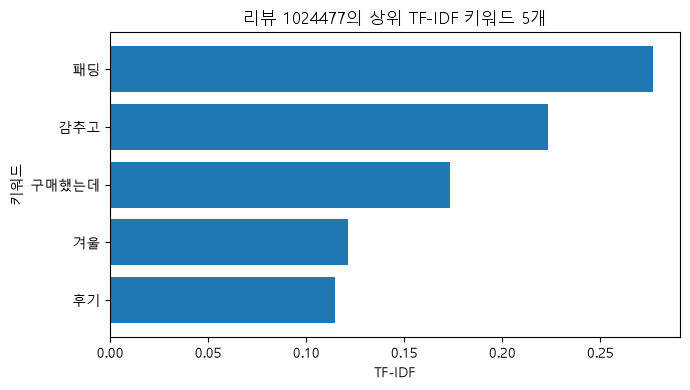


리뷰 ID: 1024477
분야 / 분류 / 상품명: 패션 / 여성의류 / OO 아** 구스코트  
원문: 드디어 겨울이 찾아왔네요. 이제부터 슬슬 겨울 패딩 장만하셔야지요? 패딩 소개해 드릴게요.   작년부터 눈여겨 보던 OO입니다. 저는 블랙90 사이즈 구매했는데 딱 잘 맞네요. 작년에 비해 저렴하게 구매해서 아주 만족해요. 신제품은 경량패딩으로 되서 3in1기능이더라구요. 경량 패딩 구매 따로 하셔야 하는 분들에겐 신제품 매장에서 확인하시라고 권하고 싶네요. 저는 경량이 있는 관계로 이 제품 구매했는데 슬림핏이라 날씬해 보여요. 하지만 안에 두껍게 입기엔 좀 불편하더라구요. 간편하게 니트 티셔츠에 입기에는 딱입니다. 아직은 초겨울이라 OO를 쭉 입고 있어요. 후기 읽으며 많이 고민했고 도움을 받아서 저도 후기 남겨봅니다.누군가에겐 도움이 되셨기를 바라는 마음에서요.   OO 패딩 좋은 건 다들 아실테고.. 롱이면서 슬림하니 감추고 싶은 부분 감추고 그러면서도 날씬하게 보이는 패딩으로 이번 겨울 멋쟁이가 되어 보시길요..

기존 전체 라벨:
 review_id  sentiment_code
   1024477             1.0

기존 속성별 주석:
 review_id  aspect_no aspect                                                    evidence_text  sentiment_code
   1024477          1    사이즈                                       저는 블랙90 사이즈 구매했는데 딱 잘 맞네요.               1
   1024477          2     가격                                         작년에 비해 저렴하게 구매해서 아주 만족해요               1
   1024477          3      핏                                       

In [3]:
# 필수 2 코드를 작성하세요.
# 1) 문서 목록 (sample_reviews 순서 그대로)
documents = sample_reviews["clean_text"].tolist()

# 2) 기본 설정 TfidfVectorizer
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)

# 3) 단어 목록과 문서×단어 표 (행: review_id, 열: 단어)
words = vectorizer.get_feature_names_out()
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(),
                        index=sample_reviews["review_id"], columns=words)

# 4) 크기, 일부, 첫 3개 리뷰의 상위 3개
print("행렬 크기(리뷰 수, 고유 표현 수):", tfidf_df.shape)
print("\n앞 3행 · 앞 10열:")
print(tfidf_df.iloc[:3, :10].round(3).to_string())
for review_id in tfidf_df.index[:3]:
    print(f"\n리뷰 {review_id}의 상위 키워드 3개:")
    print(tfidf_df.loc[review_id].nlargest(3).round(3).to_string())

# 5) 두 번째 리뷰(위치 1)의 ID와 상위 5개
target_id = sample_reviews["review_id"].iloc[1]
top5 = tfidf_df.loc[target_id].nlargest(5)
print("\ntarget_id:", target_id)
print("상위 키워드 5개:")
print(top5.round(3).to_string())

# 6) 가로 막대그래프
plot_values = top5.sort_values()
labels = plot_values.index.tolist()
if not korean_font_found:
    labels = [f"K{i}" for i in range(len(plot_values), 0, -1)]
    print("\nK번호 대응표:", dict(zip(labels, plot_values.index)))
plt.figure(figsize=(7, 4))
plt.barh(labels, plot_values.values)
plt.xlabel("TF-IDF")
plt.ylabel("키워드")
plt.title(f"리뷰 {target_id}의 상위 TF-IDF 키워드 5개")
plt.tight_layout()
plt.show()

# 7) 원문과 기존 라벨·근거
show_review_context(target_id)

### 필수 2 답변 작성란

**Q1.**

- 답변: 행렬의 행은 리뷰(문서) 100개, 열은 문서 집합에서 나온 고유 표현 3,887개, 각 칸의 값은 해당 리뷰에서 해당 표현의 TF-IDF 가중치입니다. 0.277(리뷰 1024477의 `패딩`)은 반복 정도와 희소성을 반영하고, IDF 보정과 벡터 정규화를 거친 가중치입니다. 등장 횟수가 아니므로 "0.277번 등장했다"라고 해석하면 안 됩니다.

**Q2.**

- 답변: `TfidfVectorizer()`의 기본 설정은 IDF 계산에 보정을 적용하고, 각 문서 벡터의 크기를 같게 맞추는 정규화를 합니다. 또한 기본 토큰 규칙으로 한 글자 표현 등을 제외하므로 수식으로 직접 계산한 값과 다릅니다. IDF 보정 때문에 모든 문서에 등장한 단어도 IDF가 0이 아닌 작은 양수가 되므로, 라이브러리 기본 설정에서는 반드시 0이 되지는 않습니다.

**Q3.**

- 답변: ① `패딩`(0.277): 원문의 "겨울 패딩 장만하셔야지요? 패딩 소개해 드릴게요", "OO 패딩 좋은 건", "날씬하게 보이는 패딩으로"처럼 여러 번 반복되어, 이 리뷰가 소개하는 상품 종류(겨울 패딩)를 나타냅니다. ② `감추고`(0.223): "감추고 싶은 부분 감추고 그러면서도 날씬하게 보이는"에서 두 번 쓰였고 다른 리뷰에는 드물어 높게 나왔습니다. 체형을 가려 주는 롱·슬림 디자인이라는 장점을 표현합니다. 만족 표현은 속성 `가격`, "작년에 비해 저렴하게 구매해서 아주 만족해요"(코드 1)입니다. 아쉬움 표현은 속성 `활용성`, "안에 두껍게 입기엔 좀 불편하더라구요."(코드 -1)입니다.

**Q4.**

- 답변: 단정할 수 없습니다. `구매했는데`, `후기`는 상품의 특성이 아니라 구매·후기 작성 과정을 말하는 표현이고, 조사·어미가 붙은 형태 그대로 후보에 올랐습니다. 또 기존 감정 코드는 CSV에 이미 있던 라벨일 뿐입니다. TF-IDF는 단어 가중치만 계산했고 감정을 예측하지 않았으므로 "TF-IDF가 감정을 분류했다"고 말하면 안 됩니다.

---
## 과제 1. 다른 리뷰의 키워드 해석과 소규모 문서의 한계 확인

### 문제 3-1. 가장 높은 점수의 표현을 그대로 믿어도 될까?

#### 문제 설명

필수 2의 **동일한 100개 문서로 계산한 `tfidf_df`**를 사용하여 이번에는 첫 번째 리뷰를 해석합니다. 추가로 교안의 `불량` 예시로 문서 수에 따른 기본 IDF 변화를 계산합니다. 새로운 모델이나 전처리 기법은 필요하지 않습니다.

#### 요구사항

1. 첫 번째 리뷰 ID를 `task_id`에 저장하세요. 기존 `tfidf_df`에서 이 리뷰의 상위 키워드 5개를 추출해 `task_top5`에 저장하고 출력하세요. 첫 리뷰 하나만으로 TF-IDF를 다시 계산하지 마세요.
2. 필수 2와 같은 방식으로 상위 5개 가중치를 가로 막대그래프로 그리세요.
3. `show_review_context(task_id)`로 본문과 기존 라벨·근거를 확인하세요. 가장 높은 표현이 실제로 어떤 맥락에서 쓰였는지 Q1에 설명하세요.
4. 별도의 계산 연습으로, 문서 4개 중 1개에 `불량`이 등장할 때의 기본 IDF와, `불량`이 포함된 문서가 1개 추가되어 문서 5개 중 2개에 등장할 때의 기본 IDF를 계산하세요.
5. `구분`, `N`, `DF`, `기본_IDF` 컬럼의 `idf_change` 표로 추가 전·후를 소수점 셋째 자리까지 출력하세요. 이것은 교안의 가정 예시이며 실제 CSV에 문서를 추가하는 작업이 아닙니다.

#### 해석 질문

**Q1.** 첫 번째 리뷰에서 가장 높은 TF-IDF를 가진 표현은 무엇이며, 원문에서 어떻게 쓰였나요? 상품의 핵심 특성이라고 판단해도 되나요?

**Q2.** 높은 가중치만으로 불만 여부를 판단할 수 없는 이유를 설명하세요. 실제 리뷰의 속성별 근거에서 만족과 아쉬움을 하나씩 제시하고, 교안의 `파손되어 도착`과 `파손되지 않고 도착`의 차이도 설명하세요.

**Q3.** 가정 예시의 문서 추가 전후 IDF는 어떻게 변했나요? 문서가 적을 때 이러한 변화에 주의해야 하는 이유는 무엇인가요?

**Q4.** `배송이 빨라서 만족했습니다.`와 `상품이 금방 도착해서 좋았습니다.`는 의미가 유사한가요? TF-IDF의 한계와 교안에서 언급한 보완 방법을 설명하세요. 보완 방법을 구현할 필요는 없습니다.

#### 제출 결과

- 첫 번째 리뷰의 상위 키워드 표와 막대그래프
- 원문 및 기존 라벨·근거 확인 출력
- 기본 IDF 변화 표
- Q1~Q4 답변

별도의 CSV나 그림 파일을 제출할 필요는 없습니다. 결과와 그래프를 노트북에 남기세요.


### 과제 시작 전 확인

필수 2에서 만든 tfidf_df를 그대로 사용합니다. 과제는 새 모델을 만드는 것이 아니라 같은 결과에서 다른 리뷰를 고르는 연습입니다. 가장 높은 표현을 먼저 원문에서 찾아보고 어떤 역할로 쓰였는지 설명하세요.

뒤의 문서 추가 예시는 실제 CSV와 별도입니다. N과 DF를 모두 바르게 바꾸고, 포함 문서의 비중이 어떻게 달라졌는지 설명합니다. 숫자가 내려갔다는 사실만으로 실제 불량이 줄었다고 결론 내리지 않습니다.

task_id: 1024338
go    0.294
입은    0.166
안에    0.144
요즘    0.126
제가    0.118


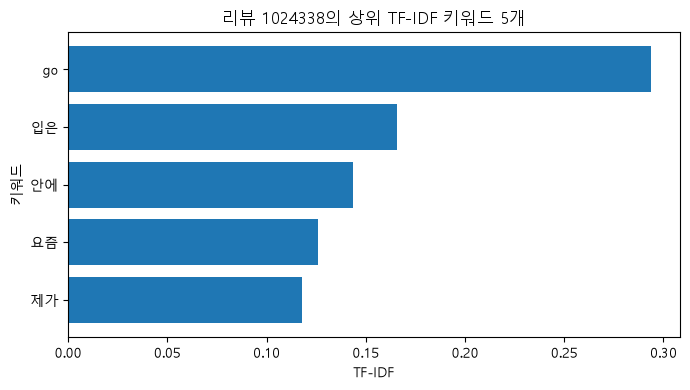


리뷰 ID: 1024338
분야 / 분류 / 상품명: 패션 / 여성의류 / OO 경량 다운 자켓
원문: 안녕하세요 이웃님들 반갑습니다. 요즘 날씨가 많이 쌀쌀해졌죠? 요즘 계절에 입으면 딱 좋을 인생 경량 패딩 하나 소개해 드릴게요.  다 함께 go go go~~  제가 입어보고 좋아서 엄마께도 구매해드렸네요. 딱 기본 스타일인데 또 입은 거 보면 깔끔하게 저렴해보이지 않는 디자인이라서 어디서 샀냐고 많이들 물어보는 옷입니다.  엄마도 제가 입은 것 보시더니 탐내셔서  주문해드렸어요. 영하로 내려가는 날씨에는 이것만 입기엔 얇지만 초겨울까지는 운동 갈때 안에 얇은 기능성 반팔 입고 요것만 입어도 꽤 따뜻해요. 색상도 디자인도 무난해서 사무실에 두고 입기도 좋고, 평소에 가볍게 나갈때 코디하기도 좋아요. 앞으로 코트를 입거나 할때 안에 내피로 활용하기도 딱일 듯요! 맘같아선 색깔별로 쟁이고 싶습니다.  20대와 50대 모두 아우르는 디자인이 무난하고 깔끔하면서 고급스러운 옷 추천합니다~~~  설명 끝! 좀 도움이 되셨나요? 그러면 좋아요 꾹 눌러 주시고 전 이만 총총총~~ 항상 여러 이웃님들께 감사드립니다. 

기존 전체 라벨:
 review_id  sentiment_code
   1024338             1.0

기존 속성별 주석:
 review_id  aspect_no aspect                                evidence_text  sentiment_code
   1024338          1    디자인   딱 기본 스타일인데 또 입은 거 보면 깔끔하게 저렴해보이지 않는 디자인이라서               1
   1024338          2     두께                                  이것만 입기엔 얇지만              -1
   1024338          3     기능 초겨울까지는 운동 갈때 안에 얇은 기능성 반팔 입고 요것만 입어도 꽤 따뜻해요.       

In [4]:
# 과제 1 코드를 작성하세요.
# 1) 첫 번째 리뷰: 기존 tfidf_df에서 상위 5개 (재계산하지 않음)
task_id = sample_reviews["review_id"].iloc[0]
task_top5 = tfidf_df.loc[task_id].nlargest(5)
print("task_id:", task_id)
print(task_top5.round(3).to_string())

# 2) 가로 막대그래프
plot_values = task_top5.sort_values()
labels = plot_values.index.tolist()
if not korean_font_found:
    labels = [f"K{i}" for i in range(len(plot_values), 0, -1)]
    print("\nK번호 대응표:", dict(zip(labels, plot_values.index)))
plt.figure(figsize=(7, 4))
plt.barh(labels, plot_values.values)
plt.xlabel("TF-IDF")
plt.ylabel("키워드")
plt.title(f"리뷰 {task_id}의 상위 TF-IDF 키워드 5개")
plt.tight_layout()
plt.show()

# 3) 원문과 기존 라벨·근거
show_review_context(task_id)

# 4) 교안의 가정 예시: '불량'의 기본 IDF 변화
before_N, before_DF = 4, 1
after_N, after_DF = 5, 2

# 5) 결과 표
idf_change = pd.DataFrame({
    "구분": ["추가 전", "추가 후"],
    "N": [before_N, after_N],
    "DF": [before_DF, after_DF],
    "기본_IDF": [log(before_N / before_DF), log(after_N / after_DF)],
})
print("\n", idf_change.round(3).to_string(index=False))

### 과제 1 답변 작성란

**Q1.**

- 답변: 가장 높은 표현은 `go`(0.294)입니다. 원문에서는 "다 함께 go go go~~"처럼 블로그식 인사·추임새로 세 번 반복되었고, 다른 리뷰에는 거의 없어 점수가 높아졌습니다. 상품의 소재·디자인·기능과는 관계없는 표현이므로 상품의 핵심 특성이라고 판단하면 안 됩니다. 이 리뷰의 상품 특성은 오히려 속성 근거의 "디자인", "얇지만", "꽤 따뜻해요" 같은 표현에서 확인됩니다.

**Q2.**

- 답변: TF-IDF는 표현의 반복과 희소성만 반영하고, 그 표현이 긍정인지 부정인지, 부정어가 붙었는지는 반영하지 않습니다. 이 리뷰에서 만족은 속성 `디자인` "깔끔하게 저렴해보이지 않는 디자인이라서"(코드 1)이고, 아쉬움은 속성 `두께` "이것만 입기엔 얇지만"(코드 -1)입니다. 그런데 상위 5개(`go`, `입은`, `안에`, `요즘`, `제가`)에는 이런 평가가 드러나지 않습니다. 교안의 `파손되어 도착`과 `파손되지 않고 도착`도 `파손`, `도착`이 똑같이 들어 있어 비슷한 가중치를 받을 수 있지만, 앞은 불만이고 뒤는 정상 배송이라는 정반대 의미입니다.

**Q3.**

- 답변: `불량`의 기본 IDF는 ln(4/1) ≈ 1.386에서 ln(5/2) ≈ 0.916으로 낮아졌습니다. 포함 문서의 비중이 1/4(25%)에서 2/5(40%)로 커졌기 때문입니다. 문서가 적으면 문서 한 개만 추가되거나 빠져도 N과 DF의 비율이 크게 바뀌어 가중치와 순위가 쉽게 흔들립니다. 따라서 값이 내려갔다고 실제 불량이 줄었다고 해석하면 안 되고, 문서 집합의 크기와 구성을 함께 밝혀야 합니다.

**Q4.**

- 답변: 두 문장은 빠른 배송에 만족했다는 점에서 의미가 유사합니다. 하지만 공통 표현이 거의 없어서(`배송이`/`상품이`, `빨라서`/`금방 도착해서`, `만족했습니다`/`좋았습니다`) TF-IDF 벡터로는 비슷하지 않게 계산됩니다. TF-IDF는 표면 단어가 일치하는지만 보고 동의어나 문맥상 의미를 반영하지 못합니다. 교안에서는 이를 보완하는 방법으로, 의미를 수치 벡터로 표현하는 **임베딩**과 문맥을 읽고 판단하는 **LLM** 기반 분석을 제시합니다.

## 개념 정리 — 결과를 읽기 전에 구분할 것

| 혼동하기 쉬운 항목 | 구분 기준 |
|---|---|
| 전체 등장 횟수 / TF / DF | 모든 문서의 반복 합계 / 지정 문서 안의 횟수 / 포함한 문서 수 |
| IDF / TF-IDF | 집합 안에서의 단어 희소성 / 특정 문서의 TF까지 반영한 값 |
| 고유 표현 수 / 등장 횟수 | 행렬의 서로 다른 열 수 / 문서들 안에서 반복한 횟수 |
| 행 위치 / 리뷰 ID | iloc의 0·1·2 / 같은 원문을 찾기 위한 식별자 |
| 앞 몇 열 / 상위 키워드 | 표 일부를 보여주는 선택 / 한 문서의 모든 열에서 큰 값 선택 |
| 정렬 / 재계산 | 이미 나온 값을 순서대로 배치 / 문서 집합으로 가중치를 새로 계산 |
| 가중치 / 감정 확률 | TF-IDF가 만든 수치 / 이번에는 예측하지 않은 정보 |
| 기존 라벨 / 새 분석 결과 | CSV에 이미 있던 코드 / 이번에 계산한 단어 가중치 |
| 계산상 특징 / 실제 핵심 정보 | 반복·희소성이 반영된 후보 / 원문과 목적을 확인해 판단할 내용 |

이번 강의의 해석 순서는 **문서 집합 확인 → 가중치와 순위 확인 → 그래프 읽기 → 원문·속성 근거 확인 → 조건을 포함한 결론 작성**입니다. 가중치를 숫자로 정확히 구하는 것과, 그 숫자로 무슨 결론을 낼 수 있는지 구분하는 것이 모두 필요합니다.

---
## 실습 마무리

1. 단순 빈도 분석만으로 문서의 특징을 찾을 때 어떤 문제가 있었나요?
2. TF와 IDF는 각각 무엇을 반영했나요?
3. 상위 키워드가 의미 있는지 무엇을 근거로 판단했나요?
4. 기본 수식의 결과와 라이브러리 기본 출력값을 구분해야 하는 이유는 무엇인가요?
5. 문서 수와 내용이 바뀌면 결과 해석에서 무엇을 주의해야 하나요?

각 질문에 1~3문장으로 답하세요.


### 실습 마무리 답변 작성란

1. 단순 빈도는 `패딩`, `입기`, 추임새처럼 여러 문서에 흔하거나 반복만 많은 표현을 높게 세어서, 그 문서만의 특징을 구분하기 어려웠습니다.

2. TF는 한 문서 안에서 표현이 반복된 정도를, IDF는 전체 문서 집합에서 그 표현이 얼마나 드문지를 반영했습니다.

3. 상위 키워드를 원문에서 찾아 쓰인 맥락을 읽고, 속성별 근거 문장과 비교했습니다. 예를 들어 `go`는 추임새이고 `패딩`은 상품 종류임을 원문으로 확인했습니다.

4. 라이브러리 기본값에는 IDF 보정과 벡터 정규화가 적용되어 수식으로 계산한 값과 크기가 다르기 때문입니다. 숫자를 비교·해석할 때 어떤 기준으로 계산했는지 밝혀야 합니다.

5. N과 DF가 바뀌면 같은 표현의 IDF와 순위도 바뀝니다. 특히 문서가 적으면 변화가 크므로, 결과에 문서 집합의 범위(이번에는 패션 분야 앞 100개 리뷰)를 함께 적고 일반화하지 않아야 합니다.